# Diffusion model

In [ ]:
!pip install -q diffusers datasets accelerate

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader, ConcatDataset, Subset
from torchvision.datasets import Flowers102
from torchvision import transforms
from diffusers import UNet2DModel, DDPMScheduler
from tqdm.auto import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

IMAGE_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 50

Device: cuda


In [ ]:
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

train_data = Flowers102(
    root="./data",
    split="train",
    download=True,
    transform=transform
)

val_data = Flowers102(
    root="./data",
    split="val",
    download=True,
    transform=transform
)

test_data = Flowers102(
    root="./data",
    split="test",
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    train_data, val_data, test_data
])

# Select 5,000 images
generator = torch.Generator().manual_seed(42)
indices = torch.randperm(
    len(full_dataset), generator=generator
)[:5000].tolist()

selected_dataset = Subset(full_dataset, indices)



100%|██████████| 345M/345M [00:14<00:00, 24.5MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.48MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 27.3MB/s]

Training images: 5000


Batch shape: torch.Size([32, 3, 64, 64])


In [ ]:
class ImageOnlyDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]
        return image


train_dataset = ImageOnlyDataset(selected_dataset)

In [ ]:
dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True
)

print("Training images:", len(train_dataset))

images = next(iter(dataloader))
print("Batch shape:", images.shape)

Training images: 5000
Batch shape: torch.Size([32, 3, 64, 64])


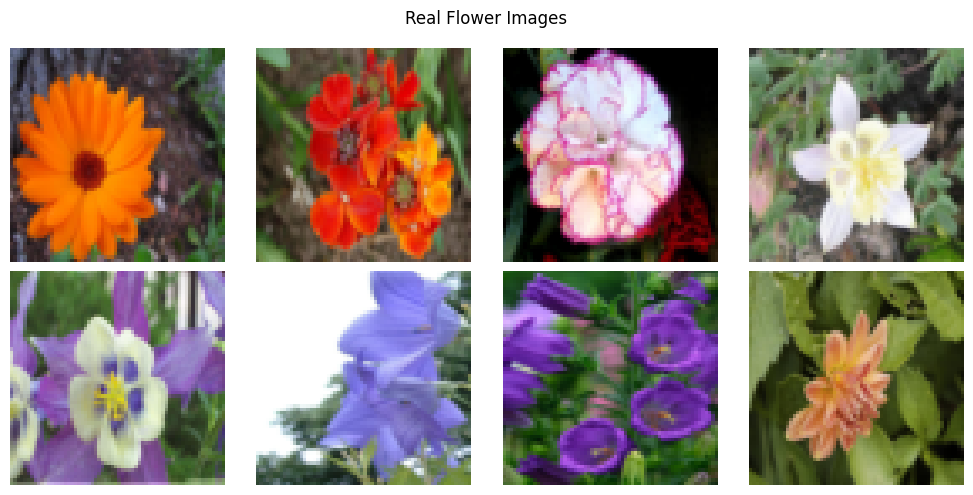

In [ ]:
def show_images(images, title="Images"):
    images = (images[:8].cpu().clamp(-1, 1) + 1) / 2

    fig, axes = plt.subplots(2, 4, figsize=(10, 5))

    for image, ax in zip(images, axes.flat):
        ax.imshow(image.permute(1, 2, 0))
        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show_images(next(iter(dataloader)), "Real Flower Images")

In [ ]:
model = UNet2DModel(
    sample_size=IMAGE_SIZE,
    in_channels=3,
    out_channels=3,
    layers_per_block=2,
    block_out_channels=(64, 128, 128),
    down_block_types=(
        "DownBlock2D",
        "DownBlock2D",
        "AttnDownBlock2D"
    ),
    up_block_types=(
        "AttnUpBlock2D",
        "UpBlock2D",
        "UpBlock2D"
    )
).to(device)

print("Parameters:", sum(
    p.numel() for p in model.parameters()
))

Parameters: 6472195


In [ ]:
# Scheduler

noise_scheduler = DDPMScheduler(
    num_train_timesteps=300,
    beta_schedule="linear",
    prediction_type="epsilon"
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4
)

In [ ]:
#Training

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    progress = tqdm(
        dataloader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for images in progress:
        images = images.to(device)

        # Generate random noise
        noise = torch.randn_like(images)

        # Choose a random timestep for each image
        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (images.shape[0],),
            device=device
        ).long()

        # Add noise according to the scheduler
        noisy_images = noise_scheduler.add_noise(
            images, noise, timesteps
        )

        # Predict the noise
        predicted_noise = model(
            noisy_images, timesteps
        ).sample

        # Compare predicted noise with actual noise
        loss = F.mse_loss(predicted_noise, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        progress.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(dataloader)
    print(f"Epoch {epoch + 1}: loss = {avg_loss:.4f}")

    # checkpoint every 5 epochs
    if (epoch + 1) % 5 == 0:
        torch.save(
            model.state_dict(),
            f"flowers_ddpm_epoch_{epoch + 1}.pth"
        )

Epoch 1/50:   0%|          | 0/156 [00:00<?, ?it/s]

Epoch 1: loss = 0.2099


Epoch 2/50:   0%|          | 0/156 [00:00<?, ?it/s]

Epoch 2: loss = 0.0992


Epoch 3/50:   0%|          | 0/156 [00:00<?, ?it/s]

...

Epoch 49/50:   0%|          | 0/156 [00:00<?, ?it/s]

Epoch 49: loss = 0.0568


Epoch 50/50:   0%|          | 0/156 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7be798aa2ac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7be798aa2ac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 50: loss = 0.0580


In [ ]:
@torch.no_grad()
def generate_images(num_images=8):
    model.eval()

    noise_scheduler.set_timesteps(
        noise_scheduler.config.num_train_timesteps,
        device=device
    )

    #  pure random noise
    images = torch.randn(
        num_images,
        3,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=device
    )

    # Gradually remove noise
    for t in tqdm(noise_scheduler.timesteps):
        model_input = noise_scheduler.scale_model_input(
            images, t
        )

        predicted_noise = model(
            model_input, t
        ).sample

        images = noise_scheduler.step(
            predicted_noise, t, images
        ).prev_sample

    # Convert from [-1, 1] to [0, 1]
    images = (images.clamp(-1, 1) + 1) / 2

    return images.cpu()

  0%|          | 0/300 [00:00<?, ?it/s]

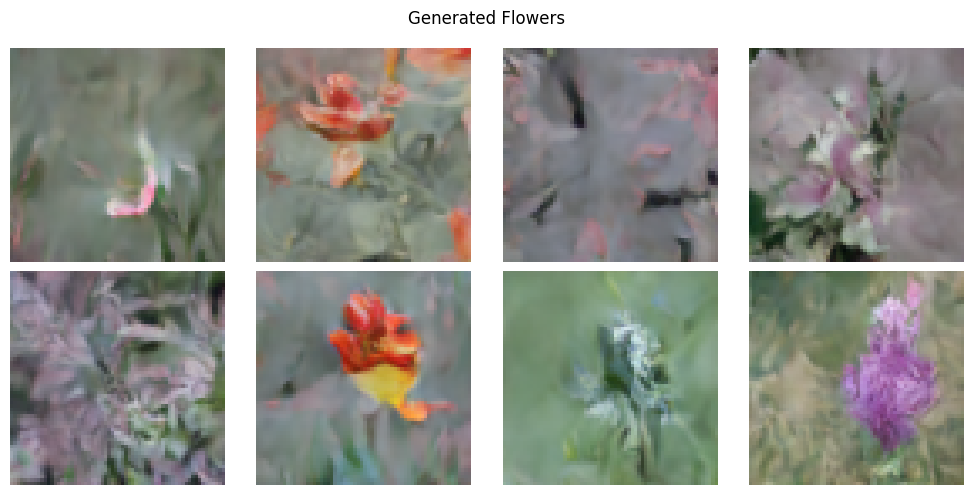

In [ ]:
generated = generate_images(8)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for image, ax in zip(generated, axes.flat):
    ax.imshow(image.permute(1, 2, 0))
    ax.axis("off")

plt.suptitle("Generated Flowers")
plt.tight_layout()
plt.show()

In [ ]:
# Save model weights
torch.save(model.state_dict(), "flowers_ddpm.pth")


model.load_state_dict(
    torch.load("flowers_ddpm.pth", map_location=device)
)

model.eval()
print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
generated = generate_images(8)
show_images(
    generated * 2 - 1,
    "Generated Flowers"
)

# DCGANS

In [ ]:
!pip install -q torchvision

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, ConcatDataset, Subset
from torchvision.datasets import Flowers102
from torchvision import transforms
from torchvision.utils import make_grid
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

IMAGE_SIZE = 64
BATCH_SIZE = 64
LATENT_DIM = 100
EPOCHS = 50
LR = 0.0002

Device: cuda


In [ ]:
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

train_data = Flowers102(
    root="./data", split="train",
    download=True, transform=transform
)

val_data = Flowers102(
    root="./data", split="val",
    download=True, transform=transform
)

test_data = Flowers102(
    root="./data", split="test",
    download=True, transform=transform
)

full_dataset = ConcatDataset([
    train_data, val_data, test_data
])

generator = torch.Generator().manual_seed(42)

indices = torch.randperm(
    len(full_dataset), generator=generator
)[:5000].tolist()

dataset = Subset(full_dataset, indices)

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True
)

print("Training images:", len(dataset))

100%|██████████| 345M/345M [00:14<00:00, 24.4MB/s]
100%|██████████| 502/502 [00:00<00:00, 910kB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 9.48MB/s]


Training images: 5000


In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()

        self.net = nn.Sequential(
            # Input: (latent_dim, 1, 1)  it is spread across channels
            nn.ConvTranspose2d(
                latent_dim, 512, 4, 1, 0, bias=False
            ),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            # 4 x 4
            nn.ConvTranspose2d(
                512, 256, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # 8 x 8
            nn.ConvTranspose2d(
                256, 128, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 16 x 16
            nn.ConvTranspose2d(
                128, 64, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 32 x 32
            nn.ConvTranspose2d(
                64, 3, 4, 2, 1, bias=False
            ),
            nn.Tanh() # output in -1 to 1 as the normalized image pixel values

            # Output: (3, 64, 64)
        )

    def forward(self, z):
        return self.net(z)

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            # Input: (3, 64, 64)
            nn.Conv2d(
                3, 64, 4, 2, 1, bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),  # Leaky relu helps to retain gradients for negative inputs

            # 32 x 32
            nn.Conv2d(
                64, 128, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # 16 x 16
            nn.Conv2d(
                128, 256, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            # 8 x 8
            nn.Conv2d(
                256, 512, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            # 4 x 4
            nn.Conv2d(
                512, 1, 4, 1, 0, bias=False
            )
            # Output: (1, 1, 1)
        )

    def forward(self, image):
        return self.net(image).view(-1)

In [ ]:
G = Generator(LATENT_DIM).to(device)
D = Discriminator().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    G.parameters(),
    lr=LR,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    D.parameters(),
    lr=LR,
    betas=(0.5, 0.999)
)

print("Generator parameters:",
      sum(p.numel() for p in G.parameters()))

print("Discriminator parameters:",
      sum(p.numel() for p in D.parameters()))

Generator parameters: 3576704
Discriminator parameters: 2765568


In [ ]:
fixed_noise = torch.randn(
    16, LATENT_DIM, 1, 1, device=device
)

Epoch 1/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 1: D Loss=0.6578, G Loss=3.4832


Epoch 2/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 2: D Loss=0.8593, G Loss=2.5261


Epoch 3/50:   0%|          | 0/78 [00:00<?, ?it/s]

...

Epoch 4/50:   0%|          | 0/78 [00:00<?, ?it/s]

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        if w.is_alive():self._shutdown_workers()
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError
: can only test a c

Epoch 4: D Loss=0.8418, G Loss=2.9405


Epoch 5/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 5: D Loss=0.7442, G Loss=2.7388


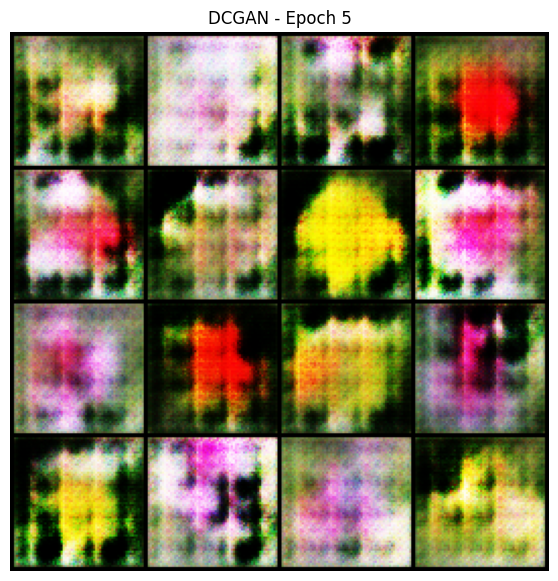

Epoch 6/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 6: D Loss=0.7687, G Loss=3.2576


Epoch 7/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 7: D Loss=0.6977, G Loss=3.3233


...

Epoch 9/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 9: D Loss=0.7471, G Loss=3.0312


Epoch 10/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 10: D Loss=0.7723, G Loss=3.0313


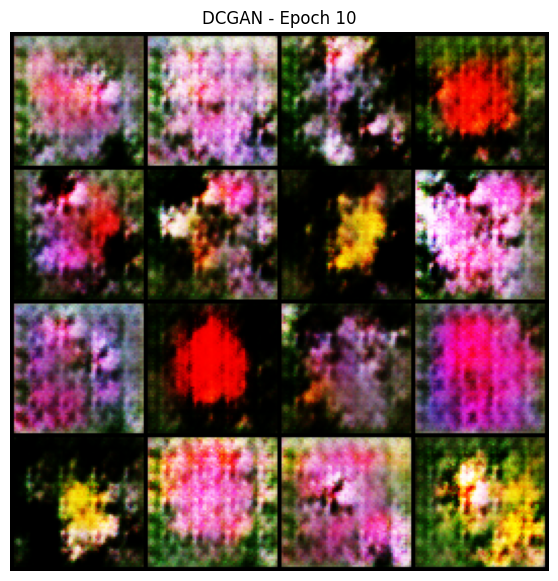

Epoch 11/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 11: D Loss=0.7739, G Loss=3.0152


Epoch 12/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 12: D Loss=0.7459, G Loss=2.9622


Epoch 13/50:   0%|          | 0/78 [00:00<?, ?it/s]

...

Epoch 14/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    assert self._parent_pid == os.getpid(), 'can only test a child process'    self._shutdown_workers()
AssertionError
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
:     can only test a child process
if w.is_alive():Exception ignored 

Epoch 14: D Loss=0.7419, G Loss=3.1556


Epoch 15/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 15: D Loss=0.7191, G Loss=3.1000


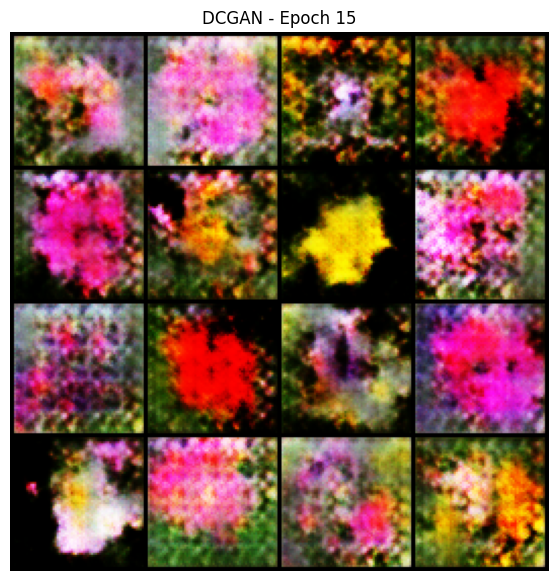

Epoch 16/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 16: D Loss=0.7587, G Loss=3.1344


Epoch 17/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 17: D Loss=0.6891, G Loss=3.1516


Epoch 18/50:   0%|          | 0/78 [00:00<?, ?it/s]

...

Epoch 19/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 19: D Loss=0.7219, G Loss=2.9735


Epoch 20/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 20: D Loss=0.7419, G Loss=3.0469


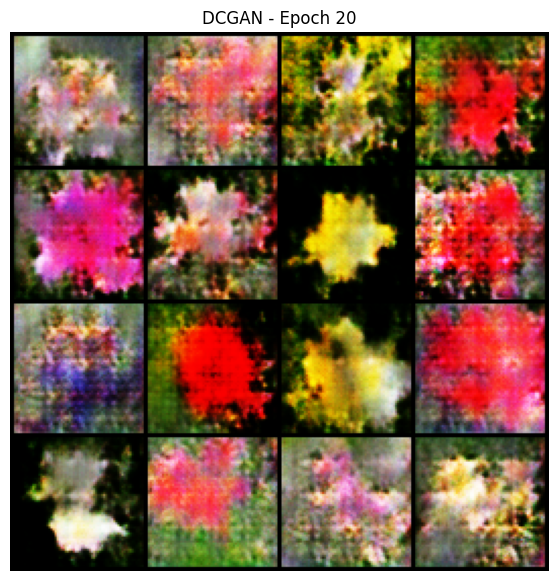

Epoch 21/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 21: D Loss=0.7700, G Loss=3.0534


Epoch 22/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 22: D Loss=0.6403, G Loss=2.9914


Epoch 23/50:   0%|          | 0/78 [00:00<?, ?it/s]

...

Epoch 24/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>self._shutdown_workers()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
self._shutdown_workers()    
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

Epoch 24: D Loss=0.6862, G Loss=3.0988


Epoch 25/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 25: D Loss=0.7424, G Loss=3.1478


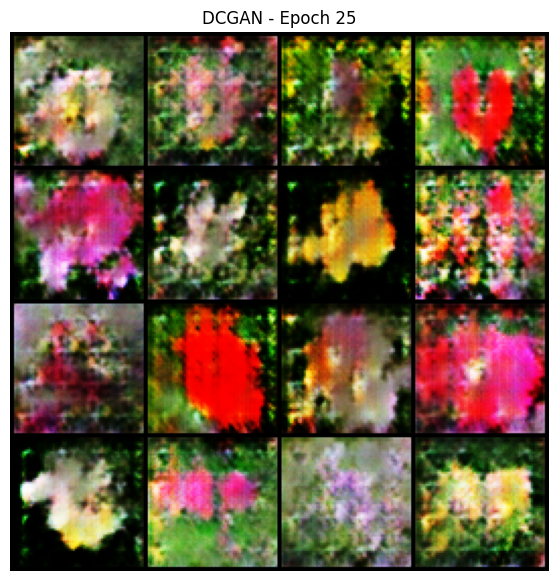

Epoch 26/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    Exception ignored in: self._shutdown_workers()
<function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    Traceback (most recent call last):
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
self._shutdown_workers()    assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    AssertionErrorif w.is_alive():
:   File "/usr/lib/python3.13/multiprocessing/pro

Epoch 26: D Loss=0.6404, G Loss=2.7823


Epoch 27/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 27: D Loss=0.6854, G Loss=2.9140


...

Epoch 29/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
Exception ignored in: AssertionError<function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>: can only test a child process

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     self._shutdown_workers()
<function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/da

Epoch 29: D Loss=0.7348, G Loss=2.9860


Epoch 30/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 30: D Loss=0.8014, G Loss=2.8343


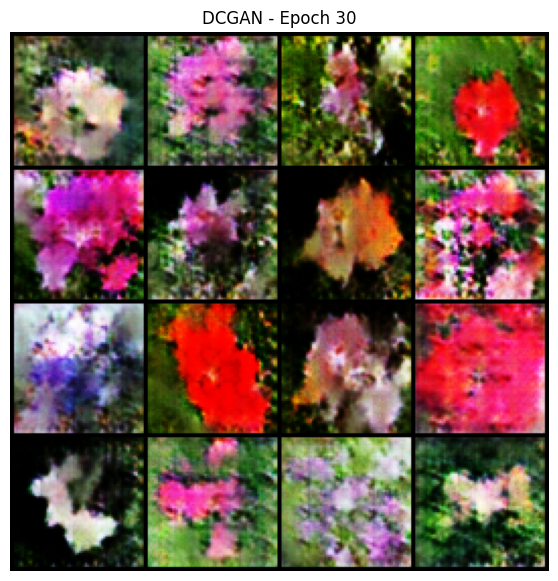

Epoch 31/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 31: D Loss=0.6314, G Loss=2.9458


Epoch 32/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 32: D Loss=0.6739, G Loss=3.0354


Epoch 33/50:   0%|          | 0/78 [00:00<?, ?it/s]

...

Epoch 34/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 34: D Loss=0.7277, G Loss=2.9812


Epoch 35/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 35: D Loss=0.6372, G Loss=2.9522


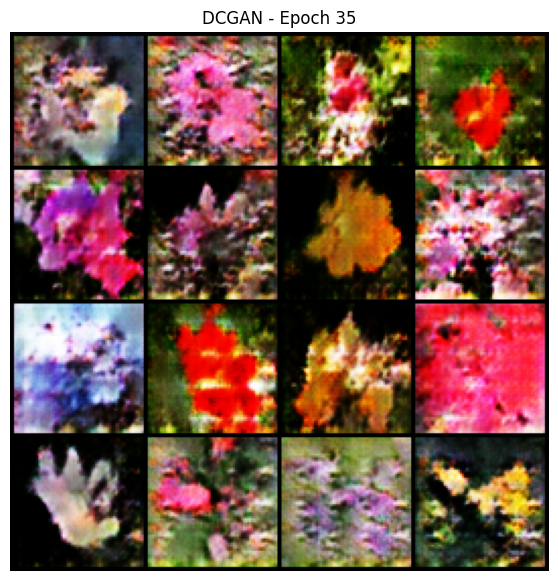

Epoch 36/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 36: D Loss=0.6748, G Loss=3.1144


Epoch 37/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 37: D Loss=0.6502, G Loss=2.9740


Epoch 38/50:   0%|          | 0/78 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 39: D Loss=0.7120, G Loss=3.0107


Epoch 40/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Exception ignored in: assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
<function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>Exception ignored in: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
    Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/pyth

Epoch 40: D Loss=0.5970, G Loss=2.7704


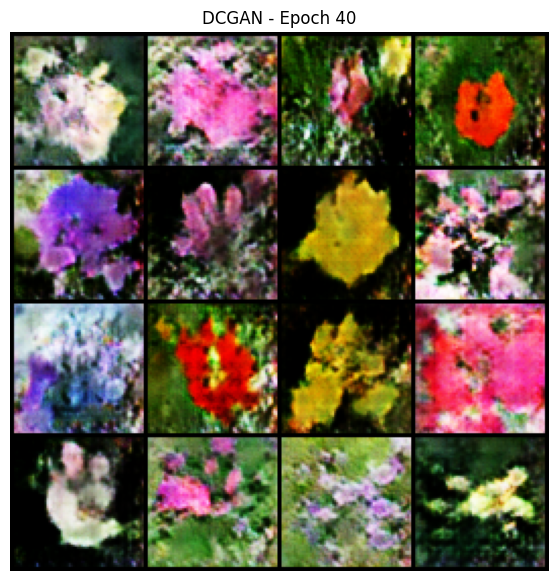

Epoch 41/50:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 41: D Loss=0.6367, G Loss=2.9399


Epoch 42/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
self._shutdown_workers()    
assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
AssertionError    if w.is_alive():: can only test a child process

  File "/usr/lib/

Epoch 42: D Loss=0.7012, G Loss=2.9388


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 44: D Loss=0.6505, G Loss=2.9572


Epoch 45/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _Multi

Epoch 45: D Loss=0.6234, G Loss=2.8968


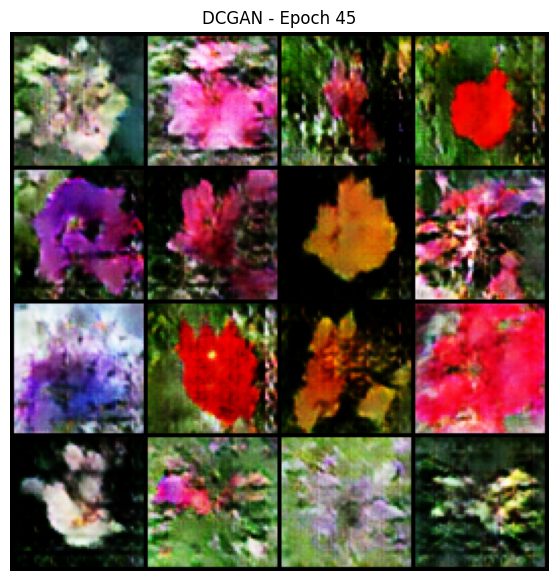

Epoch 46/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 46: D Loss=0.6494, G Loss=2.9394


Epoch 47/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
<function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>    
Traceback (most recent call last):
assert self._parent_pid == os.getpid(), 'can only test a child process'
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
AssertionError    : self._shutdown_workers()can only test a child process

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():Exception ignored 

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 49: D Loss=0.6768, G Loss=3.0295


Epoch 50/50:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfb3835eac0>assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionErrorTraceback (most recent call last):
:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
can only test a child process    
self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _Multi

Epoch 50: D Loss=0.5756, G Loss=2.8919


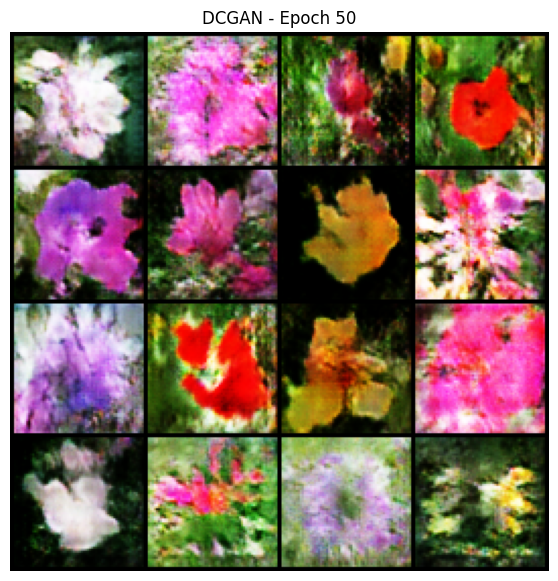

In [ ]:
#Training

G_losses = []
D_losses = []

for epoch in range(EPOCHS):
    G.train()
    D.train()

    total_G_loss = 0
    total_D_loss = 0

    progress = tqdm(
        dataloader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for real_images, _ in progress:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        real_labels = torch.ones(
            batch_size, device=device
        )
        fake_labels = torch.zeros(
            batch_size, device=device
        )

        # --------------------------------
        # 1. Train Discriminator
        # --------------------------------
        D.zero_grad(set_to_none=True)

        # Classify real images
        real_output = D(real_images)
        loss_real = criterion(
            real_output, real_labels
        )

        # Generate fake images
        noise = torch.randn(
            batch_size, LATENT_DIM, 1, 1,
            device=device
        )
        fake_images = G(noise)

        # Detach so D's update does not train G
        fake_output = D(fake_images.detach())
        loss_fake = criterion(
            fake_output, fake_labels
        )

        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D.step()

        # --------------------------------
        # 2. Train Generator
        # --------------------------------
        G.zero_grad(set_to_none=True)

        noise = torch.randn(
            batch_size, LATENT_DIM, 1, 1,
            device=device
        )
        fake_images = G(noise)

        # G wants D to classify fake images as real
        output = D(fake_images)
        loss_G = criterion(
            output, real_labels
        )

        loss_G.backward()
        optimizer_G.step()

        total_D_loss += loss_D.item()
        total_G_loss += loss_G.item()

        progress.set_postfix(
            D_loss=loss_D.item(),
            G_loss=loss_G.item()
        )

    avg_D_loss = total_D_loss / len(dataloader)
    avg_G_loss = total_G_loss / len(dataloader)

    D_losses.append(avg_D_loss)
    G_losses.append(avg_G_loss)

    print(
        f"Epoch {epoch + 1}: "
        f"D Loss={avg_D_loss:.4f}, "
        f"G Loss={avg_G_loss:.4f}"
    )

    # Save generated samples every 5 epochs
    if (epoch + 1) % 5 == 0:
        G.eval()

        with torch.no_grad():
            samples = G(fixed_noise).cpu()

        samples = (samples.clamp(-1, 1) + 1) / 2

        grid = make_grid(samples, nrow=4)

        plt.figure(figsize=(7, 7))
        plt.imshow(grid.permute(1, 2, 0))
        plt.title(f"DCGAN - Epoch {epoch + 1}")
        plt.axis("off")
        plt.show()

        torch.save(
            G.state_dict(),
            f"dcgan_generator_epoch_{epoch + 1}.pth"
        )
        torch.save(
            D.state_dict(),
            f"dcgan_discriminator_epoch_{epoch + 1}.pth"
        )

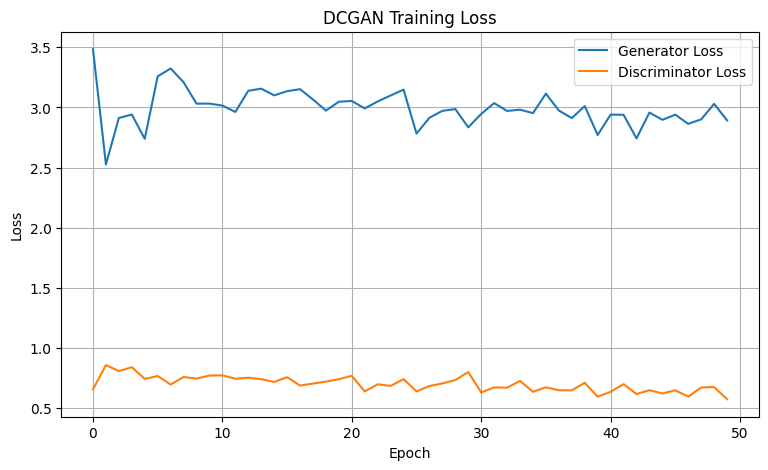

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(G_losses, label="Generator Loss")
plt.plot(D_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")
plt.legend()
plt.grid(True)
plt.show()

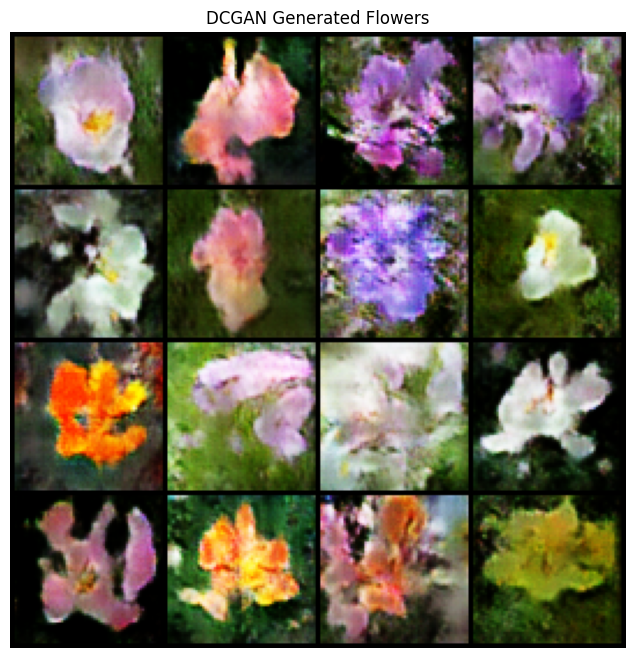

In [ ]:
G.eval()

with torch.no_grad():
    noise = torch.randn(
        16, LATENT_DIM, 1, 1, device=device
    )
    generated = G(noise).cpu()

generated = (generated.clamp(-1, 1) + 1) / 2
grid = make_grid(generated, nrow=4)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0))
plt.title("DCGAN Generated Flowers")
plt.axis("off")
plt.show()

In [ ]:
torch.save(G.state_dict(), "dcgan_generator.pth")
torch.save(D.state_dict(), "dcgan_discriminator.pth")

print("DCGAN models saved!")

DCGAN models saved!
